In [86]:
from pathlib import Path
import pandas as pd

directory = Path("../../data/cryptohftdata/derived/datasets/btcusdt_v2/time_5m-d2c874c2e5")
files = sorted(directory.glob("*.parquet"))

df = pd.concat(
    [pd.read_parquet(file) for file in files],
    ignore_index=True
).sort_values("bar_id").reset_index(drop=True)


In [87]:
import numpy as np

def validate_bars(df, expected_duration_s=60):
    required = [
        "bar_id",
        "decision_time_ns",
        "eval_time_ns",
        "t_start_ns",
        "t_end_ns",
    ]

    assert all(c in df.columns for c in required), "Lipsesc coloane"
    assert len(df) > 0, "DataFrame gol"

    results = []

    def check(name, condition):
        condition = np.asarray(condition, dtype=bool)
        bad = np.flatnonzero(~condition)

        results.append({
            "check": name,
            "status": "PASS" if len(bad) == 0 else "FAIL",
            "errors": len(bad),
        })

        if len(bad):
            print(f"\n{name}: {len(bad):,} erori")
            print("Poziții problematice:", bad[:10])

    check(
        "No missing values",
        ~df[required].isna().any(axis=1).to_numpy()
    )

    ids = df["bar_id"].to_numpy()
    start = df["t_start_ns"].to_numpy()
    end = df["t_end_ns"].to_numpy()
    decision = df["decision_time_ns"].to_numpy()
    evaluation = df["eval_time_ns"].to_numpy()

    check("Unique bar_id", ~df["bar_id"].duplicated().to_numpy())
    check("bar_id ascending", np.r_[True, np.diff(ids) > 0])
    check("bar_id consecutive", np.r_[True, np.diff(ids) == 1])

    check("Start ascending", np.r_[True, np.diff(start) > 0])
    check("End ascending", np.r_[True, np.diff(end) > 0])
    check("Decision ascending", np.r_[True, np.diff(decision) > 0])

    check("Start < End", start < end)
    check("Start <= Evaluation", start <= evaluation)
    check("Evaluation < Decision", evaluation < decision)
    check("End <= Decision", end <= decision)

    check("No overlapping bars", np.r_[True, start[1:] >= end[:-1]])

    if expected_duration_s is not None:
        check(
            "Continuous bars",
            np.r_[True, start[1:] == end[:-1]]
        )
        check(
            "Correct bar duration",
            (end - start) == int(expected_duration_s * 1e9)
        )
        check("Decision == End", decision == end)
        check("Evaluation == Decision - 1 ns", evaluation == decision - 1)

    report = pd.DataFrame(results)

    print("\n=== VALIDATION REPORT ===")
    print(report.to_string(index=False))

    print(f"\nTotal rows: {len(df):,}")
    print(f"Total failed checks: {(report.status == 'FAIL').sum()}")

    return report


report = validate_bars(df)


Correct bar duration: 141,408 erori
Poziții problematice: [0 1 2 3 4 5 6 7 8 9]

=== VALIDATION REPORT ===
                        check status  errors
            No missing values   PASS       0
                Unique bar_id   PASS       0
             bar_id ascending   PASS       0
           bar_id consecutive   PASS       0
              Start ascending   PASS       0
                End ascending   PASS       0
           Decision ascending   PASS       0
                  Start < End   PASS       0
          Start <= Evaluation   PASS       0
        Evaluation < Decision   PASS       0
              End <= Decision   PASS       0
          No overlapping bars   PASS       0
              Continuous bars   PASS       0
         Correct bar duration   FAIL  141408
              Decision == End   PASS       0
Evaluation == Decision - 1 ns   PASS       0

Total rows: 141,408
Total failed checks: 1


In [88]:
df = df.set_index("bar_id", verify_integrity=True)
df = df.sort_index()

print(df.index.is_unique)
print(df.index.is_monotonic_increasing)

True
True


In [89]:
list(df.columns)

['decision_time_ns',
 'eval_time_ns',
 't_start_ns',
 't_end_ns',
 't_open_recv_ns',
 't_close_recv_ns',
 'm_open_ms',
 'm_close_ms',
 'first_seq',
 'last_seq',
 'first_trade_id',
 'last_trade_id',
 'seg',
 'close_reason',
 'complete',
 'threshold_int',
 'feed_complete',
 'bar_open',
 'bar_high',
 'bar_low',
 'bar_close',
 'bar_n_trades',
 'bar_volume_btc',
 'bar_notional_usdt',
 'bar_vwap',
 'bar_return_log',
 'bar_oc_log',
 'bar_range_log',
 'bar_close_location',
 'bar_tfi_btc',
 'bar_tfi_usdt',
 'bar_tfi_ratio',
 'bar_count_imbalance',
 'bar_mean_trade_size_btc',
 'bar_duration_s',
 'bar_volume_rate_btc_s',
 'bar_notional_rate_usdt_s',
 'last_trade_price',
 'last_trade_age_ms',
 'tw_state_5s',
 'tw_state_30s',
 'tw_state_2m',
 'tw_state_15m',
 'tw_state_1h',
 'tw_state_4h',
 'tw_state_24h',
 'trade_count_5s',
 'volume_5s_btc',
 'notional_5s_usdt',
 'trade_rate_5s_per_s',
 'volume_rate_5s_btc_s',
 'notional_rate_5s_usdt_s',
 'tfi_5s_btc',
 'tfi_5s_usdt',
 'tfi_ratio_5s',
 'count_imba

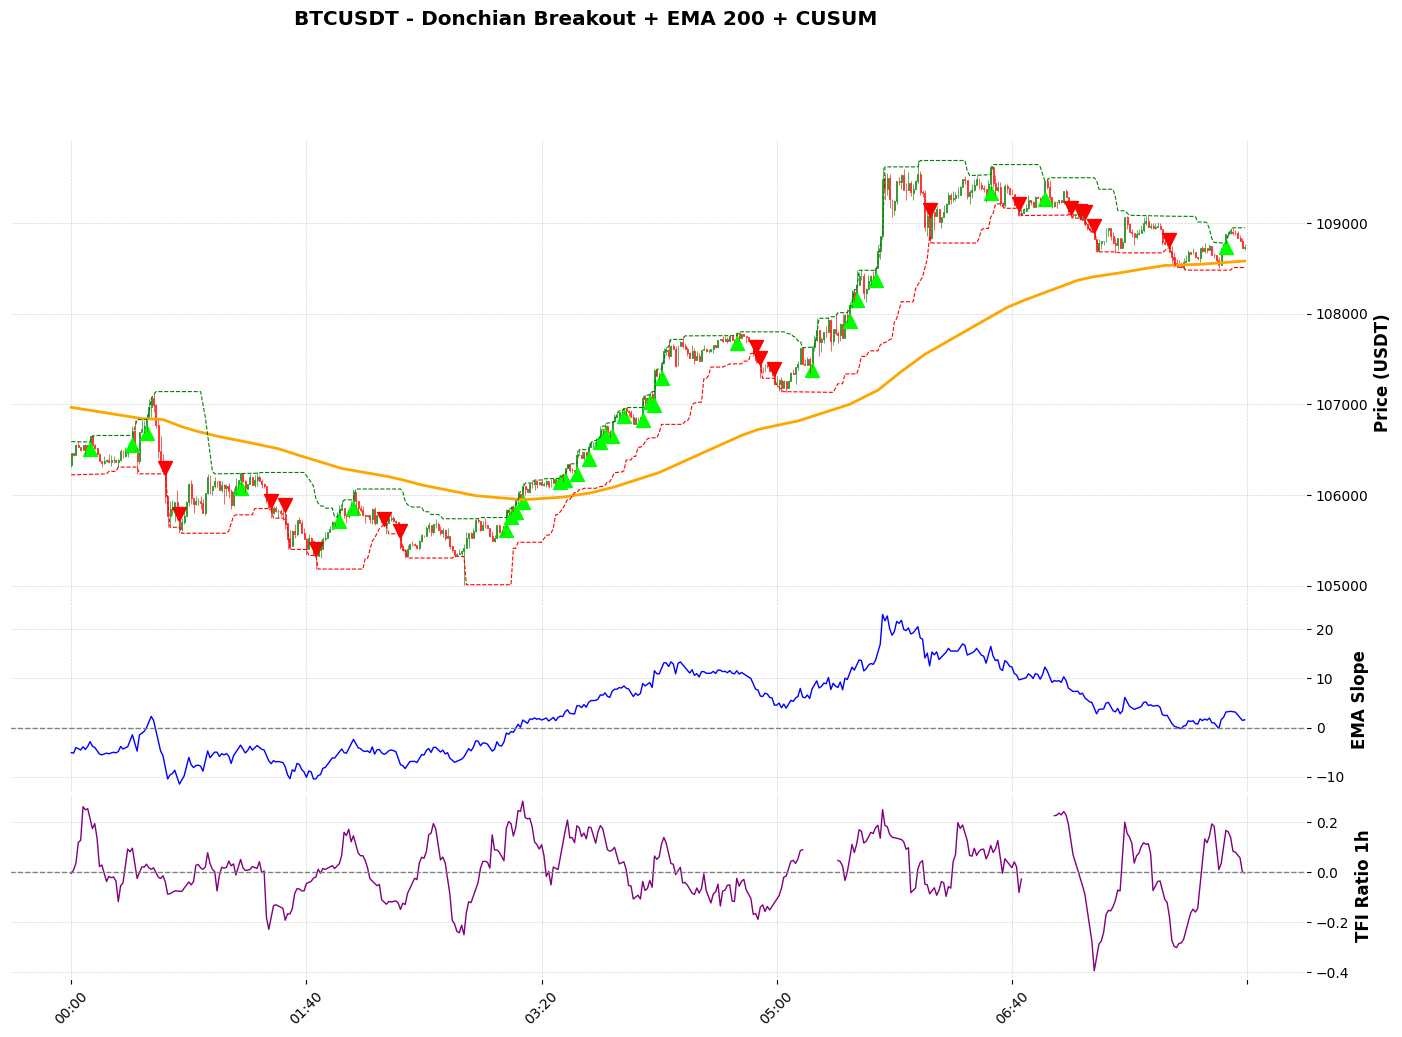

Donchian BUY: 30
Donchian SELL: 17


In [91]:
import mplfinance as mpf
import pandas as pd
import numpy as np

# ==========================================
# 1. EMA 200
# ==========================================

df["ema_200"] = df["bar_close"].ewm(
    span=200, adjust=False
).mean()

df["ema_200_slope"] = df["ema_200"].diff()

# ==========================================
# 2. DONCHIAN BREAKOUT
# ==========================================

DONCHIAN_PERIOD = 20

# Canalele folosesc doar barele precedente
# pentru a evita look-ahead bias

df["donchian_upper"] = (
    df["bar_high"]
    .rolling(DONCHIAN_PERIOD)
    .max()
    .shift(1)
)

df["donchian_lower"] = (
    df["bar_low"]
    .rolling(DONCHIAN_PERIOD)
    .min()
    .shift(1)
)

# Breakout peste/sub canal
above_upper = df["bar_close"] > df["donchian_upper"]
below_lower = df["bar_close"] < df["donchian_lower"]

# Semnal doar la primul breakout,
# nu pe fiecare bara consecutiva peste/sub canal

df["donchian_buy"] = (
    above_upper &
    ~above_upper.shift(1, fill_value=False)
)

df["donchian_sell"] = (
    below_lower &
    ~below_lower.shift(1, fill_value=False)
)

# ==========================================
# 3. Selectam barele
# ==========================================

subset = df.iloc[1000:1500
].copy()

ohlc = subset[[
    "bar_open",
    "bar_high",
    "bar_low",
    "bar_close",
    "ema_200",
    "ema_200_slope",
    "tfi_ratio_1h",
    "donchian_upper",
    "donchian_lower"
]].copy()

ohlc.columns = [
    "Open",
    "High",
    "Low",
    "Close",
    "EMA_200",
    "Slope",
    "tfi_ratio_1h",
    "Donchian_Upper",
    "Donchian_Lower"
]

# Index artificial pentru vizualizare
ohlc.index = pd.date_range(
    "2025-01-01",
    periods=len(ohlc),
    freq="min"
)

# ==========================================
# 4. Marcaje BUY / SELL
# ==========================================

buy_points = pd.Series(
    np.where(
        subset["donchian_buy"].to_numpy(),
        ohlc["Low"] * 0.9997,
        np.nan
    ),
    index=ohlc.index
)

sell_points = pd.Series(
    np.where(
        subset["donchian_sell"].to_numpy(),
        ohlc["High"] * 1.0003,
        np.nan
    ),
    index=ohlc.index
)

# ==========================================
# 5. Evenimente CUSUM la pretul de inchidere
# ==========================================


# ==========================================
# 6. Grafice suplimentare
# ==========================================

plots = [
    # EMA 200
    mpf.make_addplot(
        ohlc["EMA_200"],
        panel=0,
        color="orange",
        width=2
    ),

    # Donchian Upper
    mpf.make_addplot(
        ohlc["Donchian_Upper"],
        panel=0,
        color="green",
        linestyle="dashed",
        width=0.8
    ),

    # Donchian Lower
    mpf.make_addplot(
        ohlc["Donchian_Lower"],
        panel=0,
        color="red",
        linestyle="dashed",
        width=0.8
    ),

    # EMA Slope
    mpf.make_addplot(
        ohlc["Slope"],
        panel=1,
        color="blue",
        ylabel="EMA Slope",
        width=1
    ),

    # Trade Flow Imbalance
    mpf.make_addplot(
        ohlc["tfi_ratio_1h"],
        panel=2,
        color="purple",
        ylabel="TFI Ratio 1h",
        width=1
    )
]

# BUY - triunghi verde
if buy_points.notna().any():
    plots.append(
        mpf.make_addplot(
            buy_points,
            panel=0,
            type="scatter",
            marker="^",
            color="lime",
            markersize=100
        )
    )

# SELL - triunghi rosu
if sell_points.notna().any():
    plots.append(
        mpf.make_addplot(
            sell_points,
            panel=0,
            type="scatter",
            marker="v",
            color="red",
            markersize=100
        )
    )


# ==========================================
# 7. Stil candlestick
# ==========================================

mc = mpf.make_marketcolors(
    up="green",
    down="red",
    edge="inherit",
    wick="inherit"
)

style = mpf.make_mpf_style(
    marketcolors=mc,
    gridstyle=":",
    base_mpf_style="charles"
)

# ==========================================
# 8. Plot
# ==========================================

fig, axes = mpf.plot(
    ohlc,
    type="candle",
    style=style,
    addplot=plots,
    figsize=(18, 12),
    title="BTCUSDT - Donchian Breakout + EMA 200 + CUSUM",
    ylabel="Price (USDT)",
    panel_ratios=(5, 2, 2),
    volume=False,
    show_nontrading=False,
    warn_too_much_data=4000,
    returnfig=True
)

# Linie zero - EMA Slope
axes[2].axhline(
    y=0,
    color="gray",
    linestyle="--",
    linewidth=1
)

# Linie zero - TFI Ratio
axes[4].axhline(
    y=0,
    color="gray",
    linestyle="--",
    linewidth=1
)

mpf.show()

# ==========================================
# 9. Statistici semnale
# ==========================================

print("Donchian BUY:", subset["donchian_buy"].sum())
print("Donchian SELL:", subset["donchian_sell"].sum())


In [97]:
import numpy as np
import pandas as pd

# ==========================================
# 1. CONFIGURARE — BARE DE 1 MINUT
# ==========================================

ENTRY_PERIOD = 120
EXIT_PERIOD = 60
ATR_PERIOD = 60
STOP_BUFFER_ATR = 1.0

# Ipoteza de cost pastrata din codul tau.
TAKER_FEE = 0.0005

# Long si short.
# O singura pozitie simultan.
# Fara TP fix si fara limita temporala.
# Stop initial structural FIX + iesire Donchian dinamica.
# ret_net include comisioane, nu funding/slippage.


def run_donchian(
    df,
    entry_period=120,
    exit_period=60,
    atr_period=60,
    stop_buffer_atr=1.0,
    taker_fee=0.0005,
):
    # ======================================
    # 2. VALIDARE PARAMETRI
    # ======================================

    for name, value in [
        ("entry_period", entry_period),
        ("exit_period", exit_period),
        ("atr_period", atr_period),
    ]:
        if not isinstance(value, (int, np.integer)) or value < 1:
            raise ValueError(f"{name} trebuie sa fie un intreg pozitiv.")

    if not np.isfinite(stop_buffer_atr) or stop_buffer_atr < 0:
        raise ValueError("stop_buffer_atr trebuie sa fie finit si >= 0.")

    if not np.isfinite(taker_fee) or not 0 <= taker_fee < 1:
        raise ValueError("taker_fee trebuie sa fie in [0, 1).")

    n = len(df)

    if n == 0:
        raise ValueError("DataFrame gol.")

    # ======================================
    # 3. OHLC — PASTRAM TOATE RANDURILE
    # ======================================

    o, h, l, c = [
        pd.to_numeric(df[col], errors="coerce").to_numpy(
            dtype=float,
            na_value=np.nan,
        )
        for col in [
            "bar_open",
            "bar_high",
            "bar_low",
            "bar_close",
        ]
    ]

    valid = (
        np.isfinite(o)
        & np.isfinite(h)
        & np.isfinite(l)
        & np.isfinite(c)
        & (o > 0)
        & (h > 0)
        & (l > 0)
        & (c > 0)
        & (h >= np.maximum(o, c))
        & (l <= np.minimum(o, c))
    )

    # ======================================
    # 4. SEGMENTE CONTINUE
    #
    # O bara invalida sau un minut lipsa
    # intrerupe segmentul.
    # Indicatorii se recalculeaza separat
    # in fiecare segment.
    # ======================================

    time_ok = np.ones(n, dtype=bool)
    one_minute = np.ones(n, dtype=bool)

    if "decision_time_ns" in df.columns:
        ts = pd.to_datetime(
            df["decision_time_ns"],
            unit="ns",
            utc=True,
            errors="coerce",
        )

        time_ok = ts.notna().to_numpy()
        known_ts = ts[ts.notna()]

        if (
            not known_ts.is_monotonic_increasing
            or known_ts.duplicated().any()
        ):
            raise ValueError(
                "Timestampurile valide trebuie ordonate si unice."
            )

        one_minute = (
            ts.diff()
            .eq(pd.Timedelta(minutes=1))
            .to_numpy()
        )

    valid &= time_ok

    # linked[j] = bara j este valida si continua bara j-1.
    linked = np.zeros(n, dtype=bool)

    linked[1:] = (
        valid[1:]
        & valid[:-1]
        & one_minute[1:]
    )

    segment = np.cumsum(~linked)

    high = pd.Series(np.where(valid, h, np.nan))
    low = pd.Series(np.where(valid, l, np.nan))
    close = pd.Series(np.where(valid, c, np.nan))

    # ======================================
    # 5. CANALE DONCHIAN
    #
    # shift(1): bara curenta nu intra
    # in canalul fata de care o comparam.
    # ======================================

    def channel(series, period, how):
        return series.groupby(
            segment,
            sort=False,
        ).transform(
            lambda s: getattr(
                s.rolling(period, min_periods=period),
                how,
            )().shift(1)
        ).to_numpy()

    entry_upper = channel(high, entry_period, "max")
    entry_lower = channel(low, entry_period, "min")

    exit_upper = channel(high, exit_period, "max")
    exit_lower = channel(low, exit_period, "min")

    # ======================================
    # 6. ATR — MEDIA SIMPLA A TRUE RANGE
    #
    # La inceputul fiecarui segment folosim
    # high-low, fara close din segmentul vechi.
    # ======================================

    previous_close = close.groupby(
        segment,
        sort=False,
    ).shift(1)

    tr = pd.concat(
        [
            high - low,
            (high - previous_close).abs(),
            (low - previous_close).abs(),
        ],
        axis=1,
    ).max(axis=1)

    atr = tr.groupby(
        segment,
        sort=False,
    ).transform(
        lambda s: s.rolling(
            atr_period,
            min_periods=atr_period,
        ).mean()
    ).to_numpy()

    # ======================================
    # 7. SEMNALE CANDIDATE
    #
    # Orice close dincolo de canal poate
    # genera intrare daca suntem fara pozitie.
    # ======================================

    buy = valid & (c > entry_upper)
    sell = valid & (c < entry_lower)

    for name, values in {
        "donchian_upper": entry_upper,
        "donchian_lower": entry_lower,
        "donchian_exit_upper": exit_upper,
        "donchian_exit_lower": exit_lower,
        "atr_strategy": atr,
        "donchian_buy": buy,
        "donchian_sell": sell,
    }.items():
        df[name] = values

    # ======================================
    # 8. REZULTATE PE BARA SEMNALULUI
    # ======================================

    names = [
        "ret_gross",
        "ret_net",
        "trade_side",
        "entry_price",
        "exit_price",
        "stop_price",
        "entry_bar",
        "exit_bar",
        "initial_risk_bps",
        "holding_bars",
    ]

    out = {
        name: np.full(n, np.nan)
        for name in names
    }

    is_event = np.zeros(n, dtype=bool)
    bins = np.full(n, np.nan)

    reasons = np.full(n, None, dtype=object)
    status = np.full(n, None, dtype=object)

    # Marcaje la barele EXECUTIILOR, pentru grafic.
    entry_side = np.zeros(n, dtype=np.int8)
    exit_side = np.zeros(n, dtype=np.int8)

    entry_marks = np.full(n, np.nan)
    exit_marks = np.full(n, np.nan)

    # ======================================
    # 9. SIMULARE SECVENȚIALĂ
    # ======================================

    i = 0

    while i < n - 1:

        if not (buy[i] or sell[i]):
            i += 1
            continue

        if not (
            np.isfinite(atr[i])
            and atr[i] > 0
            and np.isfinite(exit_upper[i])
            and np.isfinite(exit_lower[i])
        ):
            i += 1
            continue

        side = 1 if buy[i] else -1
        entry_i = i + 1

        # Executam numai daca urmatoarea bara
        # este valida si continua bara semnalului.
        if not linked[entry_i]:
            i += 1
            continue

        entry_price = o[entry_i]

        # Stop structural calculat la semnal.
        # Ramane FIX pe durata tranzactiei.
        if side == 1:
            stop = (
                exit_lower[i]
                - stop_buffer_atr * atr[i]
            )
        else:
            stop = (
                exit_upper[i]
                + stop_buffer_atr * atr[i]
            )

        # Daca open-ul este deja dincolo de stop,
        # nu deschidem pozitia.
        if stop <= 0 or side * (entry_price - stop) <= 0:
            i += 1
            continue

        for name, value in {
            "trade_side": side,
            "entry_price": entry_price,
            "stop_price": stop,
            "entry_bar": entry_i,
            "initial_risk_bps": (
                abs(entry_price - stop)
                / entry_price
                * 10_000
            ),
        }.items():
            out[name][i] = value

        entry_side[entry_i] = side
        entry_marks[entry_i] = entry_price

        exit_i = None
        pending_exit = False
        data_gap = False

        # ==================================
        # 10. URMARIREA POZITIEI
        # ==================================

        for j in range(entry_i, n):

            # Nu traversam bare invalide sau goluri temporale.
            if not valid[j] or segment[j] != segment[i]:
                data_gap = True
                break

            # Iesire decisa la close-ul precedent.
            if pending_exit:
                exit_i = j
                exit_price = o[j]
                reason = "DONCHIAN_EXIT"
                break

            # Stop depasit la deschiderea barei.
            if side * (o[j] - stop) <= 0:
                exit_i = j
                exit_price = o[j]
                reason = "STOP_GAP"
                break

            # Stop atins in interiorul barei.
            stop_hit = (
                l[j] <= stop
                if side == 1
                else h[j] >= stop
            )

            if stop_hit:
                exit_i = j
                exit_price = stop
                reason = "STOP"
                break

            # Canalul de iesire evolueaza la fiecare bara.
            # Semnalul este confirmat la close.
            pending_exit = (
                c[j] < exit_lower[j]
                if side == 1
                else c[j] > exit_upper[j]
            )

        # ==================================
        # 11. TRANZACTII FARA REZULTAT OBSERVABIL
        # ==================================

        if data_gap:
            status[i] = "DATA_GAP"

            # Nu inventam exit/PnL/eticheta.
            # Cautarea continua dupa intrerupere.
            i = j + 1
            continue

        if exit_i is None:
            status[i] = "OPEN_AT_END"
            break

        # ==================================
        # 12. PNL SI META-LABEL
        # ==================================

        ratio = exit_price / entry_price

        gross = side * (ratio - 1.0)

        # Comisioane raportate la notionalul intrarii.
        net = gross - taker_fee * (1.0 + ratio)

        for name, value in {
            "ret_gross": gross,
            "ret_net": net,
            "exit_price": exit_price,
            "exit_bar": exit_i,

            # Diferenta dintre indicii barelor.
            # Nu este durata exacta a unui stop intrabar.
            "holding_bars": exit_i - entry_i,
        }.items():
            out[name][i] = value

        is_event[i] = True
        bins[i] = int(net > 0)

        reasons[i] = reason
        status[i] = "CLOSED"

        exit_side[exit_i] = side
        exit_marks[exit_i] = exit_price

        # O noua decizie poate fi luata la close-ul
        # barei de iesire, cu executie la open-ul urmator.
        i = exit_i

    # ======================================
    # 13. SALVARE IN DATAFRAME
    # ======================================

    for name, values in out.items():
        df[name] = values

    df["is_event"] = is_event
    df["bin"] = pd.array(bins, dtype="Int64")

    df["exit_reason"] = reasons
    df["trade_status"] = status

    df["actual_entry_side"] = entry_side
    df["actual_exit_side"] = exit_side
    df["actual_entry_price"] = entry_marks
    df["actual_exit_price"] = exit_marks

    # Numai tranzactii cu rezultat cunoscut.
    trades = df.loc[is_event].copy()

    stats = {
        "bare_invalide": int((~valid).sum()),

        "discontinuitati_temporale": int(
            (
                valid[1:]
                & valid[:-1]
                & ~one_minute[1:]
            ).sum()
        ),

        "semnale_candidate": int((buy | sell).sum()),
        "tranzactii_inchise": int(is_event.sum()),

        "neetichetate_date_lipsa": int(
            (status == "DATA_GAP").sum()
        ),

        "deschise_la_final": int(
            (status == "OPEN_AT_END").sum()
        ),
    }

    return trades, stats


# ==========================================
# 14. RULARE
# ==========================================

trades, stats = run_donchian(
    df,
    entry_period=ENTRY_PERIOD,
    exit_period=EXIT_PERIOD,
    atr_period=ATR_PERIOD,
    stop_buffer_atr=STOP_BUFFER_ATR,
    taker_fee=TAKER_FEE,
)

print(f"Donchian: intrare {ENTRY_PERIOD} / iesire {EXIT_PERIOD}")

for name, value in stats.items():
    print(f"{name}: {value:,}")

if "decision_time_ns" not in df.columns:
    print(
        "Fara decision_time_ns: fiecare rand este presupus "
        "o bara consecutiva de 1 minut."
    )

# ==========================================
# 15. VALIDARE SI RAPORT
# ==========================================

if trades.empty:
    print("\nNu exista tranzactii inchise cu rezultat observabil.")

else:
    signal_positions = np.flatnonzero(
        df["is_event"].to_numpy()
    )

    assert trades["bin"].notna().all()
    assert trades["ret_gross"].notna().all()
    assert trades["ret_net"].notna().all()

    assert (
        trades["entry_bar"].to_numpy() > signal_positions
    ).all()

    assert (
        trades["exit_bar"] >= trades["entry_bar"]
    ).all()

    assert (
        trades["bin"].astype(int)
        == (trades["ret_net"] > 0).astype(int)
    ).all()

    print(
        "\nWin rate brut:",
        f"{100 * (trades['ret_gross'] > 0).mean():.2f}%",
    )

    print(
        "Win rate net:",
        f"{100 * trades['bin'].mean():.2f}%",
    )

    print(
        "Mean gross:",
        f"{10_000 * trades['ret_gross'].mean():.3f} bps",
    )

    print(
        "Mean net:",
        f"{10_000 * trades['ret_net'].mean():.3f} bps",
    )

    print(
        "Median net:",
        f"{10_000 * trades['ret_net'].median():.3f} bps",
    )

    print(
        "Distanta mediana pana la stop:",
        f"{trades['initial_risk_bps'].median():.2f} bps",
    )

    print(
        "Bare intre intrare si iesire — mediana:",
        f"{trades['holding_bars'].median():.1f}",
    )

    print("\nMotive de iesire:")
    print(trades["exit_reason"].value_counts())

    summary = trades.groupby("trade_side").agg(
        trades=("ret_net", "size"),
        win_rate_net_pct=("bin", "mean"),
        mean_gross_bps=("ret_gross", "mean"),
        mean_net_bps=("ret_net", "mean"),
        median_holding_bars=("holding_bars", "median"),
    )

    summary["win_rate_net_pct"] *= 100
    summary["mean_gross_bps"] *= 10_000
    summary["mean_net_bps"] *= 10_000

    summary.index = summary.index.map({
        -1.0: "SHORT",
        1.0: "LONG",
    })

    print("\nRezultate pe directie:")
    display(summary.round(3))

    display(trades[[
        "trade_side",
        "entry_price",
        "stop_price",
        "exit_price",
        "exit_reason",
        "initial_risk_bps",
        "holding_bars",
        "ret_gross",
        "ret_net",
        "bin",
    ]].head(20))

Donchian: intrare 120 / iesire 60
bare_invalide: 71
discontinuitati_temporale: 141,329
semnale_candidate: 0
tranzactii_inchise: 0
neetichetate_date_lipsa: 0
deschise_la_final: 0

Nu exista tranzactii inchise cu rezultat observabil.
